# 02. Build a card that adapts

Turn a plant record into a reusable, readable, accessible React Native component.

**45 minutes including practice · Seedling**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-02) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can pass data and callbacks into a reusable component.
- You can predict how row and column layouts change their main axis.
- You can make a plant card usable with larger text and assistive technology.

## Before you begin

You can describe the app’s runtime layers from lesson 01.

You can read an object and pass a function as an argument.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


A plant card seems simple until you try three names, a narrow phone, and a larger text setting. “Fern” fits almost anywhere. “Lemon tree beside the east balcony door” needs room. A useful component expresses the relationship between a photograph, a title, and an action while leaving enough freedom for real content.

In this lesson, the same card receives different plant summaries without copying its markup. You will connect the visible result to its inputs, explore layout rules, and check what a person using a screen reader or keyboard needs to understand the action. The browser lab models layout choices; confirm final React Native layout in Expo.


## Pass the record in, and report the action out

Props are the named inputs a parent gives to a child component. A card might receive a nickname and a function to call when pressed. The parent still decides what selecting a plant means. This lets the card display a search result, a recent discovery, or a garden item without having to know which screen contains it.

The teaching type PlantSummary deliberately contains only id, nickname, and scientificName. It is a small display shape, not a replacement for the full Plant contract. A full saved record has revision information, timestamps, ownership, and other fields. Naming the teaching shape avoids suggesting that a three-field object can be sent anywhere the production contract expects a complete record.

Read the callback in the example carefully. onPress receives a function that will run later. Writing onPress={onSelect(plant.id)} would call the function while building the screen. Writing onPress={() => onSelect(plant.id)} waits for the reader’s press. A child should not change the object it receives; it should report the action to the owner of that information.


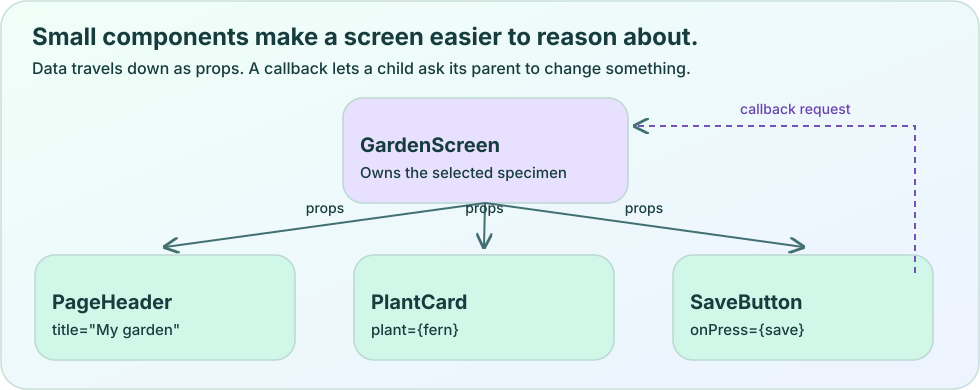

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Components, props, and callbacks</title><desc id="desc">GardenScreen gives props to PageHeader, PlantCard, and SaveButton. SaveButton calls a callback to ask for a change. The owner decides how state changes.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">Small components make a screen easier to reason about.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Data travels down as props. A callback lets a child ask its parent to change something.</text><rect x="343" y="98" width="285" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><text x="360" y="152" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">GardenScreen</text><text x="360" y="178" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Owns the selected specimen</text><rect x="35" y="255" width="260" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><text x="52" y="309" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">PageHeader</text><text x="52" y="335" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">title=&quot;My garden&quot;</text><path d="M485 203L165 247" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="325.0" y="213.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">props</text><rect x="354" y="255" width="260" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><text x="371" y="309" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">PlantCard</text><text x="371" y="335" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">plant={fern}</text><path d="M485 203L484 247" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="484.5" y="213.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">props</text><rect x="673" y="255" width="260" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><text x="690" y="309" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">SaveButton</text><text x="690" y="335" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">onPress={save}</text><path d="M485 203L803 247" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="644.0" y="213.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">props</text><path d="M915 273V126H635" fill="none" stroke="#7351b7" stroke-width="2" stroke-dasharray="6 5" marker-end="url(#arrow)"/><text x="740" y="114" font-size="14" fill="#6842ac" font-weight="500" text-anchor="start">callback request</text></g></svg>'))


**Teaching component: PlantSummaryCard.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { Pressable, StyleSheet, Text, View } from "react-native";

export type PlantSummary = {
  id: string; nickname: string; scientificName: string | null;
};
type Props = { plant: PlantSummary; onSelect: (id: string) => void };
export function PlantSummaryCard({ plant, onSelect }: Props) {
  return (
    <Pressable
      accessibilityRole="button"
      accessibilityLabel={`Open ${plant.nickname}`}
      onPress={() => onSelect(plant.id)}
      style={({ pressed }) => [styles.card, { opacity: pressed ? 0.8 : 1 }]}
    >
      <View style={styles.mark}><Text accessible={false}>🌿</Text></View>
      <View style={styles.copy}>
        <Text style={styles.name}>{plant.nickname}</Text>
        <Text>{plant.scientificName ?? "Identification uncertain"}</Text>
      </View>
    </Pressable>
  );
}
const styles = StyleSheet.create({
  card: { flexDirection: "row", alignItems: "center", gap: 12,
    padding: 16, borderRadius: 24, minHeight: 88,
    backgroundColor: "#E5FFF1" },
  mark: { width: 48, height: 48, alignItems: "center", justifyContent: "center" },
  copy: { flex: 1, gap: 4 },
  name: { fontSize: 20, fontWeight: "700", color: "#12382B" },
});
```


## Use the two layout axes intentionally

Each View arranges its own children. flexDirection chooses the main axis. With row, the children are arranged across the available width; with column, they are arranged down the available height. justifyContent distributes space along that main axis. alignItems controls alignment across the other axis. Changing the direction changes what “along” and “across” mean.

In the card, the marker has a fixed width because its decorative job is predictable. The text container uses flex: 1 so it can occupy remaining room. The text is not assigned a fixed height. That allows a long name to wrap and a larger system font to increase the card’s height. Setting the whole card to height: 88 would remove that freedom.

Numeric padding creates interior space. gap separates children. A border radius changes the corners, not the layout relationship. Start with these structural choices before adding glow or blur. If the label is clipped, increasing the shadow will not help. In the lab, change direction first and explain which axis changed, then reduce the available width and watch which content needs room.


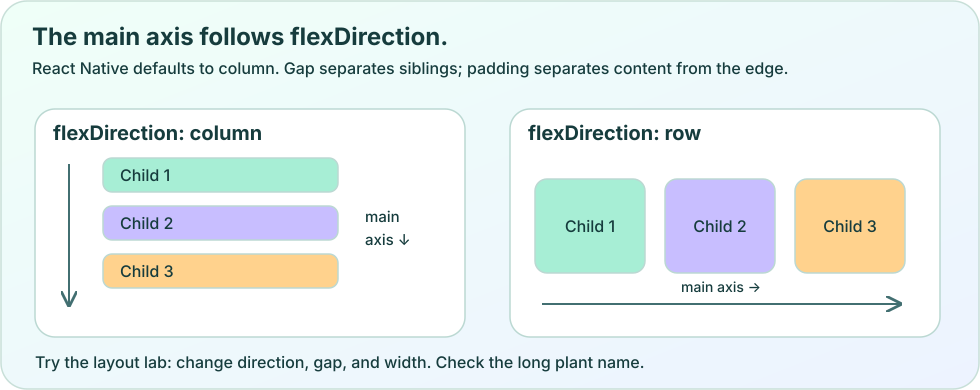

In [3]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Flexbox main axes</title><desc id="desc">Two containers compare a column with a vertical main axis and a row with a horizontal main axis. Three children retain their order. A narrow screen still needs readable text.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">The main axis follows flexDirection.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">React Native defaults to column. Gap separates siblings; padding separates content from the edge.</text><rect x="35" y="109" width="430" height="228" rx="20" fill="#fff" stroke="#bbd8d2" stroke-width="1.5"/><text x="53" y="140" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">flexDirection: column</text><rect x="103" y="158" width="235" height="34" rx="9" fill="#a7eed5" stroke="#bbd8d2" stroke-width="1.5"/><text x="120" y="181" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Child 1</text><rect x="103" y="206" width="235" height="34" rx="9" fill="#c8beff" stroke="#bbd8d2" stroke-width="1.5"/><text x="120" y="229" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Child 2</text><rect x="103" y="254" width="235" height="34" rx="9" fill="#ffd28d" stroke="#bbd8d2" stroke-width="1.5"/><text x="120" y="277" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Child 3</text><path d="M69 164L69 305" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="365" y="222" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">main</text><text x="365" y="245" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">axis ↓</text><rect x="510" y="109" width="430" height="228" rx="20" fill="#fff" stroke="#bbd8d2" stroke-width="1.5"/><text x="528" y="140" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">flexDirection: row</text><rect x="535" y="179" width="110" height="94" rx="12" fill="#a7eed5" stroke="#bbd8d2" stroke-width="1.5"/><text x="590" y="232" font-size="16" fill="#163c3d" font-weight="500" text-anchor="middle">Child 1</text><rect x="665" y="179" width="110" height="94" rx="12" fill="#c8beff" stroke="#bbd8d2" stroke-width="1.5"/><text x="720" y="232" font-size="16" fill="#163c3d" font-weight="500" text-anchor="middle">Child 2</text><rect x="795" y="179" width="110" height="94" rx="12" fill="#ffd28d" stroke="#bbd8d2" stroke-width="1.5"/><text x="850" y="232" font-size="16" fill="#163c3d" font-weight="500" text-anchor="middle">Child 3</text><path d="M542 304L900 304" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="721.0" y="292.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">main axis →</text><text x="35" y="368" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Try the layout lab: change direction, gap, and width. Check the long plant name.</text></g></svg>'))


## Render a list without losing the identity of its rows

A reusable card becomes more valuable when a list creates one for each record. FlatList is designed for lists whose content can extend beyond the visible area. The list needs a stable key for each item so React can associate a rendered row with the same logical record when ordering or contents change.

Use the specimen’s id as that key. An array position is a description of where an item currently sits, not of which plant it is. If the first record is removed, every later array position changes. Two plants can also share a nickname or scientific name, so those labels are poor identity keys.

The second teaching file imports the display component and supplies two sample records. The callback shows an alert simply to make the press visible. Later, you will replace that response with navigation. The sample data does not come from a server and does not claim to persist. Keeping that boundary explicit makes the next lessons’ added responsibilities easier to see.


**Teaching screen: PlantList.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { Alert, FlatList, Text } from "react-native";
import { PlantSummaryCard, type PlantSummary } from "./PlantSummaryCard";

const examples: PlantSummary[] = [
  { id: "lemon_east", nickname: "East balcony lemon", scientificName: null },
  { id: "lemon_west", nickname: "West window lemon", scientificName: null },
];
export default function PlantList() {
  return (
    <FlatList
      data={examples}
      keyExtractor={(plant) => plant.id}
      contentContainerStyle={{ padding: 20, gap: 12 }}
      renderItem={({ item }) => (
        <PlantSummaryCard plant={item}
          onSelect={(id) => Alert.alert("Selected specimen", id)} />
      )}
      ListEmptyComponent={<Text>
        Your first plant will appear here. Use Scan to add a specimen.
      </Text>}
    />
  );
}
```


## Make the action understandable without its decoration

A screen reader needs to know what the card does. The Pressable has a button role and a label that includes the plant nickname. That label remains meaningful even if the decorative leaf is never announced. An icon by itself does not tell a reader whether pressing it opens details, marks a favorite, or deletes a record.

Give important actions enough room to operate. This card’s padding and minimum height make its press area much larger than the text alone. On the web, verify keyboard focus is visible and that the action works from the keyboard. On a phone, turn on the platform’s screen reader and listen to the label. A browser’s automated checks cannot substitute for that native reading order.

The current production PlantCard adds a separate options button and an accessibility action for removal. It does not rely only on the left-swipe gesture. That matters because a reader may never discover or be able to perform the gesture. When you add a gesture shortcut, preserve a clear alternative action. Keep delete separate from opening the card so the two purposes are not hidden behind the same label.


> **Decoration must leave the words readable**
>
> A vivid translucent surface still needs strong text contrast. Test the opaque fallback, longer names, large text, keyboard focus, and screen-reader labels before judging the card complete.


## Separate a visual improvement from a new responsibility

The repository’s real PlantCard uses the shared theme, translated copy, authenticated private photos, navigation, and deletion state. You can recognize the same outer structure in the smaller teaching component: a pressable surface, a picture area, and flexible details. Production behavior grows around that understandable structure rather than requiring a completely different mental model.

When reviewing your card, change one input at a time. Try a null scientificName, a long nickname, and two specimens with the same name. Then change text size and available width. Explain whether each result comes from the data, the layout, or the action callback. This habit makes debugging specific: “the text container needs room to grow” is actionable, while “the screen feels broken” is not.


## Experiment: predict, change, explain

Choose column or row, then vary the gap and available width. Before changing a control, predict whether the three conceptual boxes will fit. Defaults are column, a 12-pixel gap, and 300 pixels of width. The drawing uses fixed boxes and does not measure font size or real text wrapping. Use the browser lab and Expo exercise for richer card behavior, then test font scaling on a device.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [4]:
def draw_layout(direction='column', gap=12, width=300):
    # This SVG is a conceptual drawing, not React Native's text/layout engine.
    height = 290 if direction == 'column' else 160
    pieces = []
    for i, (label, color) in enumerate([('Photo', '#a7eed5'), ('Plant name', '#d5c6ff'), ('Action', '#ffd899')]):
        x, y = (20, 28 + i * (52 + gap)) if direction == 'column' else (15 + i * (78 + gap), 45)
        pieces.append(f'<rect x="{x}" y="{y}" width="78" height="48" rx="10" fill="{color}" stroke="#6c8d80"/>')
        pieces.append(f'<text x="{x+7}" y="{y+29}" font-size="11" fill="#173c3d">{label}</text>')
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">' + ''.join(pieces) + '</svg>'))
    needed = 30 + 3 * 78 + 2 * gap if direction == 'row' else 118
    print(f'Conceptual content width: {needed}px. Available width: {width}px.')
    print('Overflow: choose wrapping or a vertical layout.' if needed > width else 'The drawn boxes fit. Real text still needs font-scale testing.')

explore(draw_layout, direction=['column', 'row'], gap=(0, 32, 4), width=(180, 400, 20))

def card_label(plant):
    return plant['nickname'] + ' · ' + (plant.get('scientificName') or 'Identification uncertain')

assert 'uncertain' in card_label({'id': 'fern_01', 'nickname': 'Kitchen fern'})
assert card_label({'id': 'fern_02', 'nickname': 'Patio fern', 'scientificName': 'Example species'}) == 'Patio fern · Example species'


interactive(children=(Dropdown(description='direction', options=('column', 'row'), value='column'), IntSlider(…

## Make a prediction of your own

Write the main-axis direction for the React Native default.

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [5]:
your_answer = None  # Replace with 'column' or 'row'.
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer == 'column':
    print('Correct. '+'The React Native default is column. The main axis therefore runs from top to bottom.')
else:
    print('Revisit your prediction. '+'The React Native default is column. The main axis therefore runs from top to bottom.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. A card has flexDirection: "row". Which property distributes its children along that row?**

1. borderRadius
2. justifyContent
3. alignItems

**2. Why should two lemon-tree cards use different keys?**

1. Keys are decorative labels shown on screen.
2. Every card needs a new random key on every render.
3. Each key should identify its particular specimen even when the list changes.

**3. What is the best response when a larger system font clips the nickname?**

1. Allow the text and card to grow and recheck the layout.
2. Disable font scaling everywhere.
3. Replace the nickname with an unlabeled icon.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [6]:
quiz = [{'question': 'A card has flexDirection: "row". Which property distributes its children along that row?', 'options': ['borderRadius', 'justifyContent', 'alignItems'], 'answer': 1, 'explanation': 'justifyContent acts along the main axis, which row makes horizontal. alignItems works across that axis. A border radius changes corner shape and does not distribute children.'}, {'question': 'Why should two lemon-tree cards use different keys?', 'options': ['Keys are decorative labels shown on screen.', 'Every card needs a new random key on every render.', 'Each key should identify its particular specimen even when the list changes.'], 'answer': 2, 'explanation': 'Stable specimen IDs let React associate each row with its logical record. Random keys destroy that continuity; a shared species label cannot distinguish the two trees.'}, {'question': 'What is the best response when a larger system font clips the nickname?', 'options': ['Allow the text and card to grow and recheck the layout.', 'Disable font scaling everywhere.', 'Replace the nickname with an unlabeled icon.'], 'answer': 0, 'explanation': 'The content should remain readable at the reader’s preferred size. Flexible text space and minimum rather than fixed height preserve that room. Removing labels or disabling scaling avoids the symptom by removing access.'}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Create three cards from one component

Use the teaching card in a separate Expo learning copy and make its behavior understandable with short, long, and missing data.

1. Render three PlantSummary objects with stable, different IDs. Make two share the same scientific name.
2. Give one specimen a long nickname and another a null scientificName.
3. Supply one onSelect callback from the parent and show the selected ID.
4. Compare a narrow layout with a larger text setting and remove fixed heights that clip words.
5. Operate the card with assistive technology and, on web, a keyboard. Record the announced action and the visible focus behavior.

### Check your result

- [ ] All three cards use the same component and preserve their separate IDs.
- [ ] The uncertain-identification fallback appears for null data.
- [ ] Long text wraps without hiding the action.
- [ ] The card’s accessible name describes opening the named plant.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

Treat the marker as fixed decoration and the text container as flexible content. The nullish-coalescing operator chooses a fallback for null or undefined.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
Create one array of three objects and feed it to FlatList with keyExtractor={(plant) => plant.id}. Keep the text container at flex: 1, use minHeight on the card, and avoid a fixed height on either text element. Pass onSelect as a callback from the list. The shared species name affects the visible description, while the distinct id determines which specimen is selected.
```

</details>


## Explain it in your own words

If the same card appears in both Search and My Garden, which information should be passed as props and which decision should remain with the parent screen?

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/components/PlantCard.tsx](../../../src/components/PlantCard.tsx) — Shows the production row structure, navigation callback, flexible details, options action, and stable specimen data.

- [src/components/ui.tsx](../../../src/components/ui.tsx) — Collects reusable screens, buttons, typography, and feedback surfaces.

- [src/theme/preferences.tsx](../../../src/theme/preferences.tsx) — Supplies shared colors and translated words to components.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [React Native layout with Flexbox](https://reactnative.dev/docs/flexbox)
- [React Native accessibility](https://reactnative.dev/docs/accessibility)
- [React Native FlatList](https://reactnative.dev/docs/flatlist)
- [Passing props to a component](https://react.dev/learn/passing-props-to-a-component)


## Carry these ideas forward

- Props let one component display different records without copying its structure.
- Layout direction determines the main axis; content needs room to respond to width and text size.
- A stable record ID and an understandable action label solve different problems.
